# Derive QC reports from RABIES outputs

This notebook provides a template for reading RABIES outputs using RUBELLA, and then generating customizable QC plots including measurements of network specificity using the RABIES Dice overlap approach, and group-level statistical summary reports. 
This is examplified separately for global connectivity, dual regression and seed-based connectivity analysis.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob
from rubella import plotting
from matplotlib.backends.backend_pdf import PdfPages

%matplotlib inline

## Select inputs
### load RABIES outputs into a DataObject

In [6]:
'''
Input parameters for brain plotting function, which are tuned to the example dataset
'''
slice_selection=[31, 29, 27, 24, 22, 19, 17, 15]
crop_edges=[14,14]
plane='coronal'


In [7]:
'''
Fetch the RABIES template files, here I am selecting the EPI template because data was preprocessed with --bold_only in RABIES
'''
from rubella.datasets import fetch_rabies_templates
EPICOMMON_files = fetch_rabies_templates('EPI')
template_file = EPICOMMON_files['template']

# the fetcher has also pulled a set of anatomical seeds available within RABIES
print(EPICOMMON_files['seeds'].keys())

dict_keys(['ACA_seed', 'AMYG_seed', 'basal_ganglia_seed', 'ECT_AI_seed', 'HIP_seed', 'HY_seed', 'MO_seed', 'ORB_limbic_seed', 'RSP_seed', 'SS_dorsal_seed', 'SS_frontal_seed', 'THAL_seed', 'VIS_seed'])


In [8]:

'''
Now I specify the set of RABIES output paths for the specific run I want to QC.
I am using a syntax where there is the name for the preprocessing folder (rabies_out_name) 
and the name for the confound correction folder (CR_name). Then I create a folder for the 
QC figures to be saved in for this specific dataset.

The timeseries are loaded into a DataObject at the last line.
'''

rabies_out_name = 'rabies_117_Cryo_mediso_v_20261027'
CR_name = f'FD_cut30frames_bandpass0.01-0.2_cut30edges_mot6_aCompCor_smooth5'
os.makedirs(f'figures_QC/{rabies_out_name}/{CR_name}', exist_ok=True)

rabies_out = f'/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/{rabies_out_name}'
brain_mask_file = f'{rabies_out}/bold_datasink/commonspace_mask/commonspace_template_brain_mask_resampled.nii.gz'

from rubella.data_obj import DataObject
timeseries_file_list = glob.glob(f'{rabies_out}/{CR_name}/confound_correction_datasink/cleaned_timeseries/*/*_cleaned.nii.gz')
timeseries_file_list.sort()
censoring_file_list = glob.glob(f'{rabies_out}/{CR_name}/confound_correction_datasink/frame_censoring_mask/*/*_frame_censoring_mask.csv')

data_obj = DataObject(brain_mask_file, timeseries_file_list, img_id_list=None, fname_split='_cleaned', censoring_file_list=censoring_file_list, verbose=True)


/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/rabies_117_Cryo_mediso_v_20261027/FD_cut30frames_bandpass0.01-0.2_cut30edges_mot6_aCompCor_smooth5/confound_correction_datasink/cleaned_timeseries/_split_name_sub-091_ses-1_task-rest_acq-EPI_bold/sub-091_ses-1_task-rest_acq-EPI_bold_cleaned.nii.gz
/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/rabies_117_Cryo_mediso_v_20261027/FD_cut30frames_bandpass0.01-0.2_cut30edges_mot6_aCompCor_smooth5/confound_correction_datasink/cleaned_timeseries/_split_name_sub-092_ses-1_task-rest_acq-EPI_bold/sub-092_ses-1_task-rest_acq-EPI_bold_cleaned.nii.gz
/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/rabies_117_Cryo_mediso_v_20261027/FD_cut30frames_bandpass0.01-0.2_cut30edges_mot6_aCompCor_smooth5/confound_correction_datasink/cleaned_timeseries/_split_name_sub-093_ses-1_task-rest_acq-EPI_bold/sub-093_ses-1_task-rest_acq-EPI_bold_cleaned.nii.gz
/media/DATA3/gdesrosiersgregoire/preproc/117_Cryo_mediso_v/rabies_117_Cryo_medi

## Generating a standard report for seed-based analysis

In [9]:
import rubella.qc.utils as qc_utils
from rubella.qc.report import group_stats_QC_plot

In [10]:
'''
Compute seed-based connectivity for all the built-in seeds that we fetched above
'''
seed_names = ['SS_frontal_seed','SS_dorsal_seed','MO_seed','ACA_seed','RSP_seed','ECT_AI_seed','ORB_limbic_seed','VIS_seed',
              'THAL_seed','basal_ganglia_seed','HIP_seed','AMYG_seed','HY_seed']
seed_set_name = 'RABIES_seeds'

SBC_dict = {}
seed_arr_dict = {}
from rubella.basic_fc import seed_based_FC
for seed_name in seed_names:
    seed_file = EPICOMMON_files['seeds'][seed_name]
    seed_arr_dict[seed_name] = data_obj._load_img_to_masked_array(seed_file, data_type='mask')
    SBC_dict[seed_name] = seed_based_FC(timeseries_dict=data_obj.timeseries_dict, brain_mask=data_obj.brain_mask_file, img_id_list=data_obj.img_id_list, seed_roi=seed_arr_dict[seed_name], z_corr=False)



        size: (83, 127, 64) vs (65, 47, 64)
        spacing: (0.15000000596046448, 0.15000000596046448, 0.15000000596046448) vs (0.18888890743255615, 0.4000000059604645, 0.15000000596046448)

        The image is resampled onto the brain mask grid, with the assumption that
        both images are already aligned in physical space.
        

        size: (83, 127, 64) vs (65, 47, 64)
        spacing: (0.15000000596046448, 0.15000000596046448, 0.15000000596046448) vs (0.18888890743255615, 0.4000000059604645, 0.15000000596046448)

        The image is resampled onto the brain mask grid, with the assumption that
        both images are already aligned in physical space.
        

        size: (83, 127, 64) vs (65, 47, 64)
        spacing: (0.15000000596046448, 0.15000000596046448, 0.15000000596046448) vs (0.18888890743255615, 0.4000000059604645, 0.15000000596046448)

        The image is resampled onto the brain mask grid, with the assumption that
        both images are already aligned

/tmp/ipykernel_30012/3324225429.py:23: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "bbox" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.savefig(fig_path, bbox='tight')


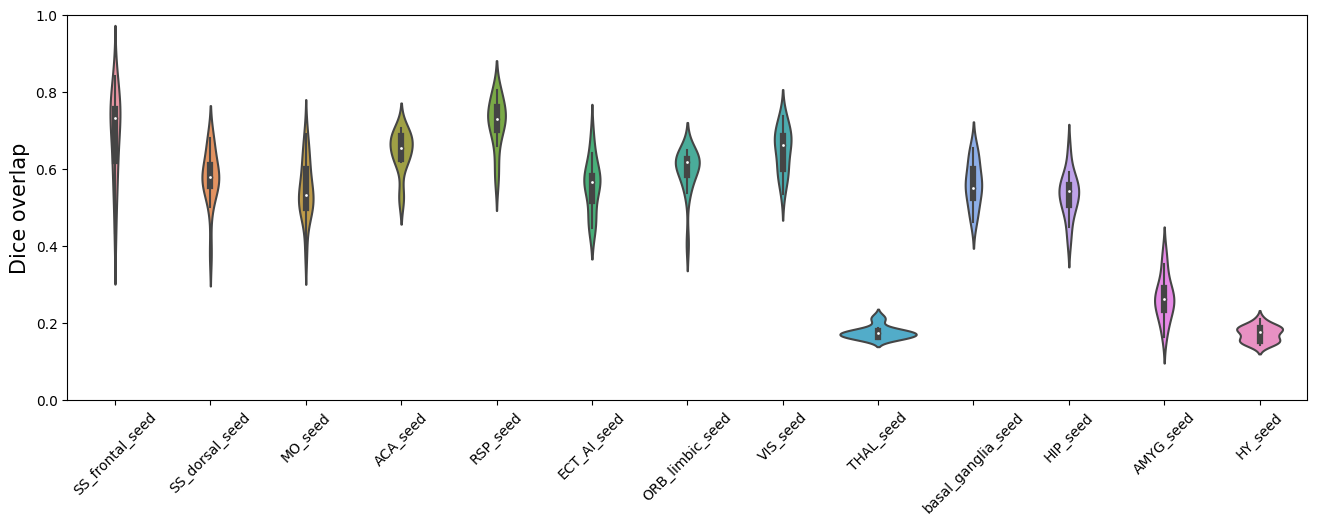

In [11]:
'''
Plot the distribution of network specificity (Dice) for each seed
'''

dice_l = []
title_l = []

for seed_name in seed_names:
    dice_list = qc_utils.get_dice_list(SBC_dict[seed_name], avg_FC=None, avg_type='median', top_percent=10, seed_mask_arr=seed_arr_dict[seed_name])

    dice_l += dice_list
    title_l += [seed_name]*len(dice_list)
        
import seaborn as sns
fig,ax = plt.subplots(1,1,figsize=(16,5))
sns.violinplot(ax=ax, y=dice_l, x=title_l)

ax.tick_params(axis='x', rotation=45)
ax.set_ylim([0,1])
ax.set_ylabel('Dice overlap', fontsize=15)

fig_path = f'figures_QC/{rabies_out_name}/{CR_name}/SBC_dice_{seed_set_name}_{rabies_out_name}_N53unilateral.png'
fig.savefig(fig_path, bbox='tight')

Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]


Text(0.5, 0.98, 'Seed: SS_frontal_seed')

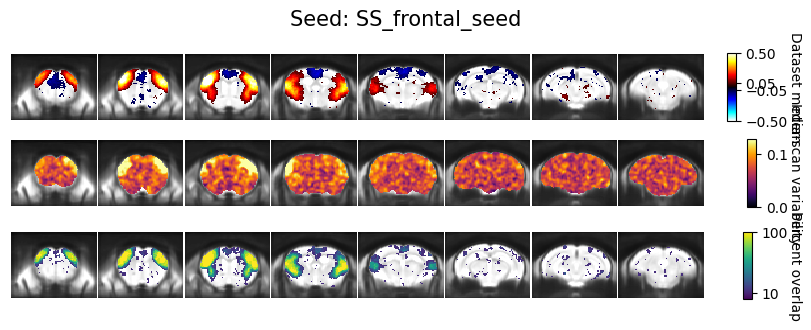

In [12]:
'''
Here is an example of the group-level statisical maps that can be generated using group_stats_QC_plot().

This is displaying 1) the group averaga, 2) the group standard deviation, and 3) the overlap of the 
top 10% of voxels across subjects for a given seed-based connectivity map.
'''
seed_name = 'SS_frontal_seed'
fig,axes = group_stats_QC_plot(SBC_dict[seed_name], brain_mask_file, template_file, slice_selection, include_stat=['avg', 'sd', 'overlap'], qc_data_dict = {})
fig.suptitle('Seed: '+seed_name, fontsize=15)

In [13]:
'''
Now this cell loops across all seeds and stores all the figures into a PDF so it is convenient to scroll 
through all seeds.
'''
fig_set = {}
for seed_name in seed_names:
    fig,axes = group_stats_QC_plot(SBC_dict[seed_name], brain_mask_file, template_file, slice_selection, include_stat=['avg', 'sd', 'overlap'], qc_data_dict = {})
    fig.suptitle('Seed: '+seed_name, fontsize=15)
    fig_set[seed_name] = fig
    plt.close(fig)

# Save all figures into one PDF
pdf_path = f"figures_QC/{rabies_out_name}/{CR_name}/SBC_group_stats_{seed_set_name}_{rabies_out_name}.pdf"
with PdfPages(pdf_path) as pdf:
    for seed_name in seed_names:
        fig = fig_set[seed_name]
        pdf.savefig(fig)


Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]


Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 

### RABIES-style scatter plot of network detectability X confound metrics

Below shows how one can generate the RABIES scatter plots of network X confound that allows to dectect individual outliers in the datasets and see if there is group-level association between network measures and confounds (see https://rabies.readthedocs.io/en/latest/explanation/distribution_plot.html).

At the moment, to generate these reports you need to have run the --data_diagnosis RABIES step with at least one input to --seed_list so that we can load some of the metrics from data_diagnosis_datasink/dataset_diagnosis/sample_distributions/seed_FC0_outlier_detection.csv.

In [14]:
'''
This cell loads the QC metrics from the RABIES CSV and organizes it into a dictionary format that is compatible with the
plot_QC_distributions() function.
'''
from rabies.analysis_pkg.diagnosis_pkg.dataset_QC import plot_QC_distributions
group_qc_csv = f'{rabies_out}/{CR_name}/data_diagnosis_datasink/dataset_diagnosis/sample_distributions/seed_FC0_outlier_detection.csv'
group_qc_df = pd.read_csv(group_qc_csv)


qc_metric_dict = {'FD-DVARS corr.':[], '$CR_{SD}$':[], 'Mean FD (mm)':[], 'Degrees of freedom':[]}
for img_id in data_obj.img_id_list:
    for df_id in list(group_qc_df['scan ID']):
        if img_id==df_id:
            sub_df = group_qc_df[group_qc_df['scan ID']==df_id]
            qc_metric_dict['FD-DVARS corr.'].append(sub_df['FD-DVARS corr.'].values[0])
            qc_metric_dict['$CR_{SD}$'].append(sub_df['$CR_{SD}$'].values[0])
            #qc_metric_dict['CR $R^{2}$'].append(sub_df['CR_VE'].values[0])
            qc_metric_dict['Mean FD (mm)'].append(sub_df['mean FD'].values[0])
            if 'tDOF' in sub_df:
                qc_metric_dict['Degrees of freedom'].append(sub_df['tDOF'].values[0])

if len(qc_metric_dict['Degrees of freedom'])==0:
    qc_metric_dict.pop('Degrees of freedom')

for key in qc_metric_dict:
    qc_metric_dict[key] = np.array(qc_metric_dict[key])

fd_qc_dict = {}
fd_qc_dict['Mean FD (mm)'] = qc_metric_dict['Mean FD (mm)']

#also set the bounds for the scatter plots
x_bounds_dict = {'Network specificity (Dice)':[0,1.0]}
y_bounds_dict = {'FD-DVARS corr.':[-0.1,1.0], 'CR $R^{2}$':[0.0,1.0]}


Text(0.5, 0.98, 'SS_frontal_seed')

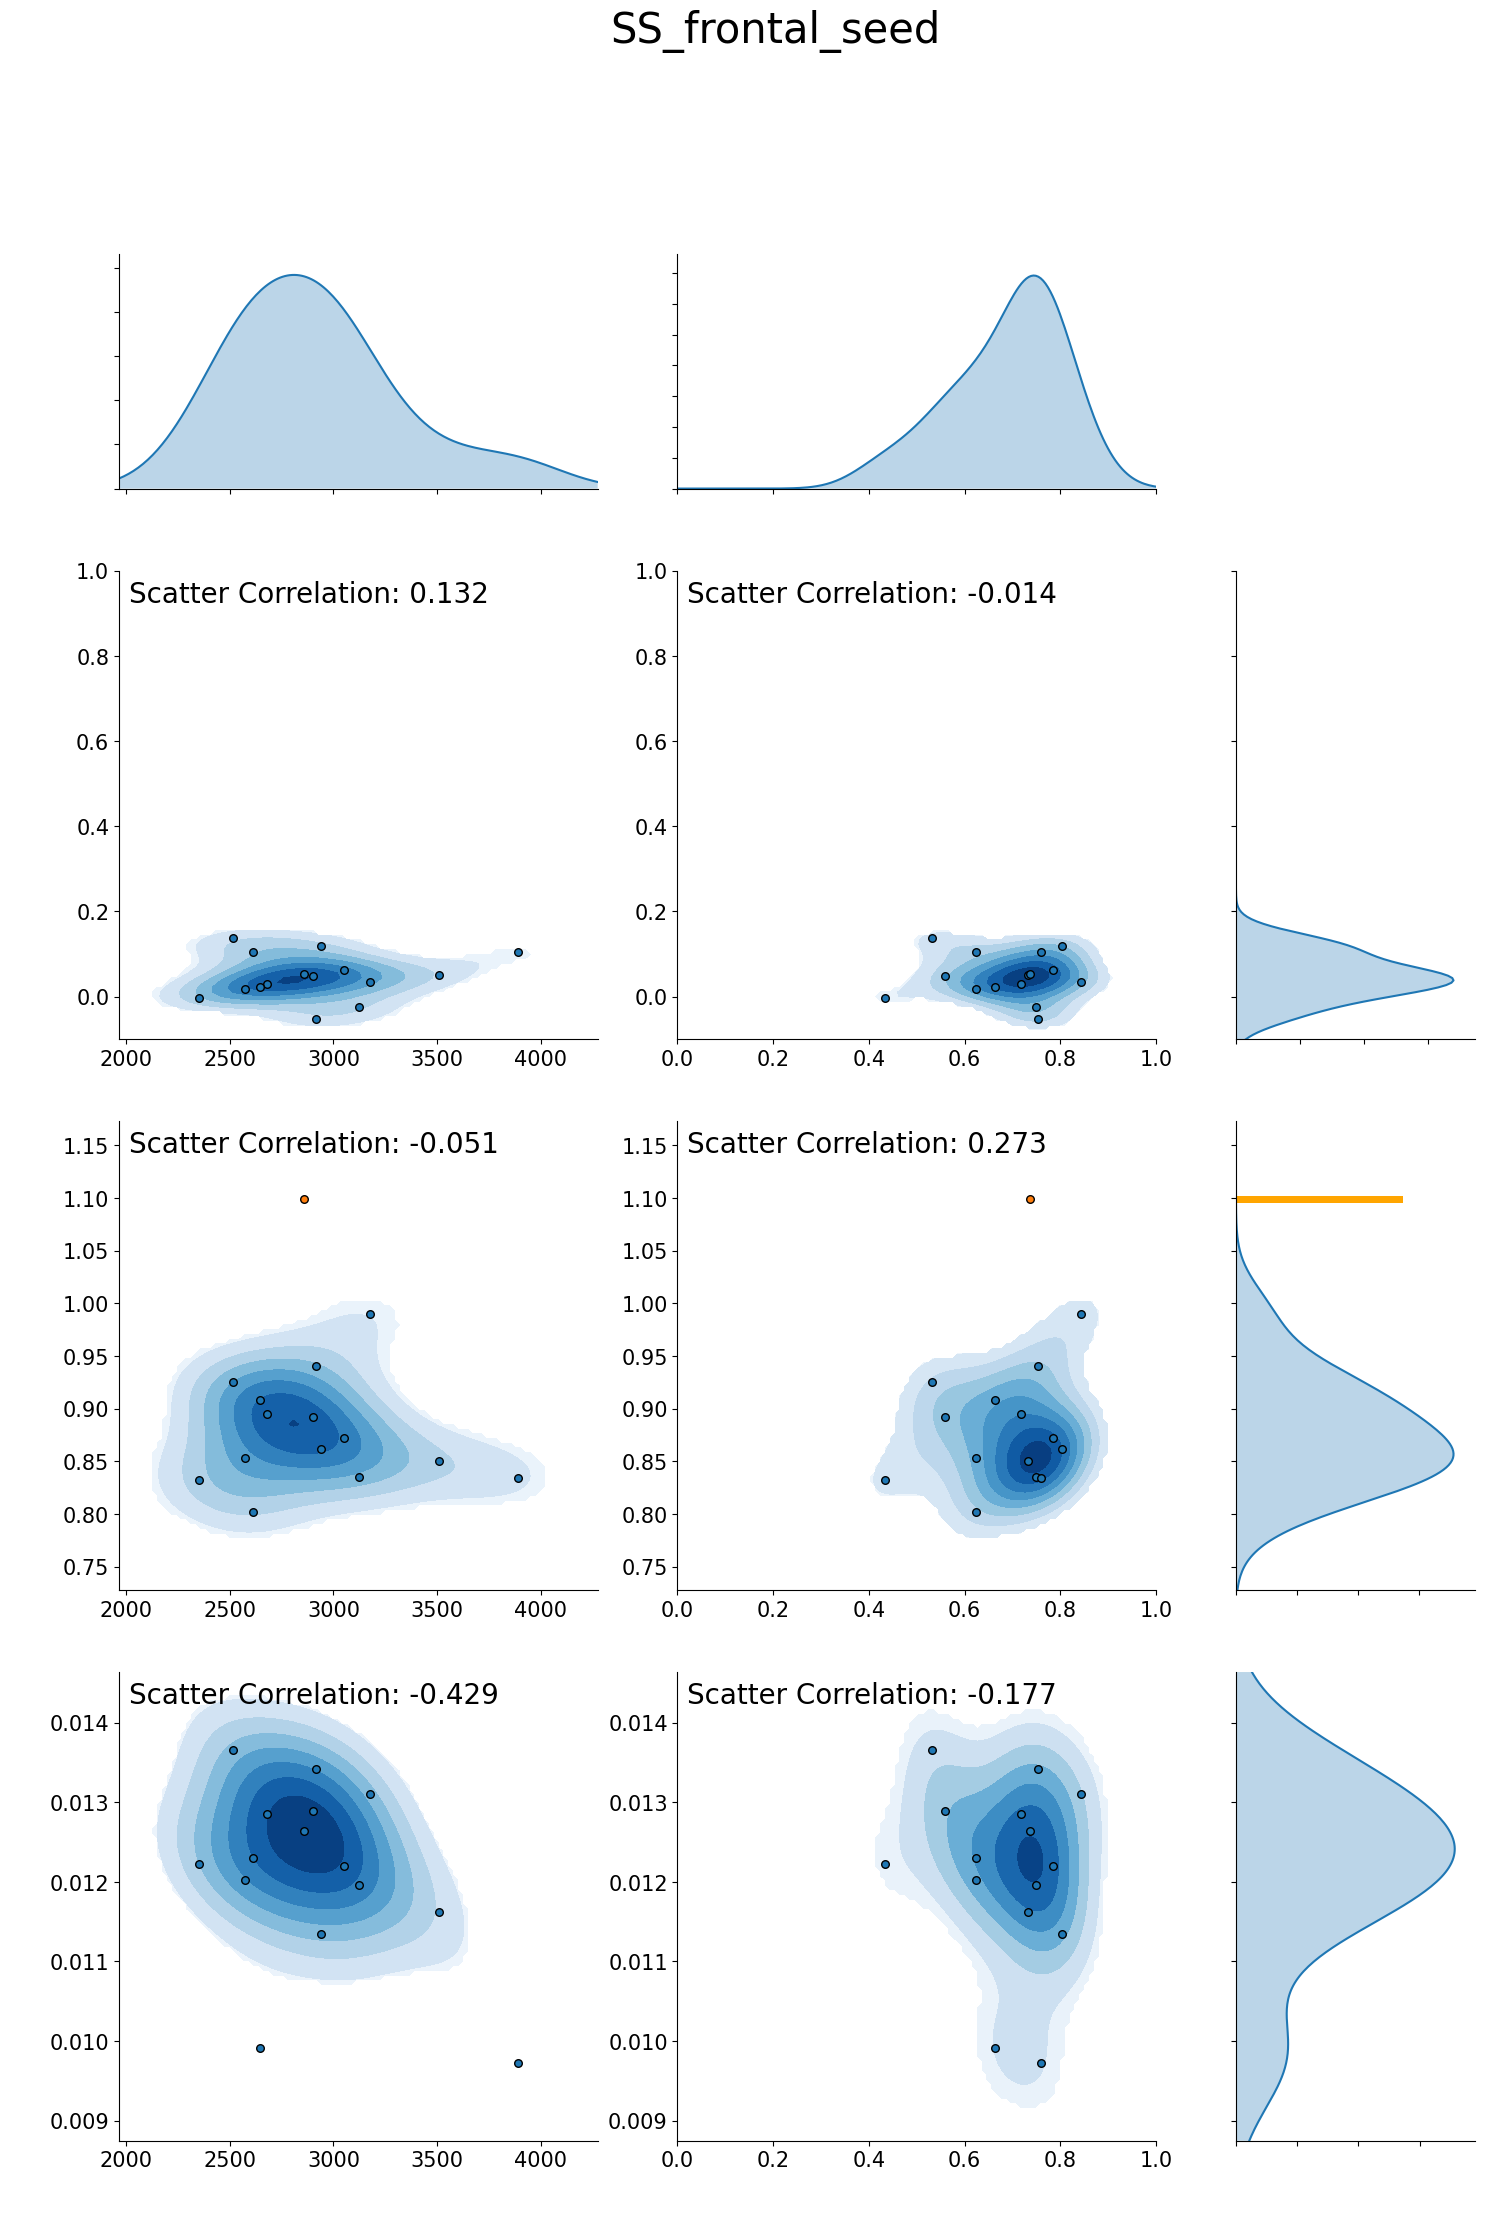

In [15]:
'''
Here I first generate an example with the first seed
'''

seed_name = 'SS_frontal_seed'
dice_list = qc_utils.get_dice_list(SBC_dict[seed_name], avg_FC=None, avg_type='median', top_percent=10, seed_mask_arr=seed_arr_dict[seed_name])
FC_amp_list = [np.sqrt(SBC_dict[seed_name][img_id] ** 2).sum() for img_id in SBC_dict[seed_name]]
net_metric_dict = {'Network amplitude':np.array(FC_amp_list), 'Network specificity (Dice)':np.array(dice_list)}

fig = plot_QC_distributions(net_metric_dict,qc_metric_dict, x_bounds_dict=x_bounds_dict, y_bounds_dict=y_bounds_dict, QC_inclusion=None, scan_QC_thresholds={}, outlier_threshold=3.5, write_corr=True)
fig.suptitle(seed_name, fontsize=30)


In [ ]:
'''
Now we can loop through all seeds to store the outputs in a single PDF file.
'''
fig_set = {}
for seed_name in seed_names:

    dice_list = qc_utils.get_dice_list(SBC_dict[seed_name], avg_FC=None, avg_type='median', top_percent=10, seed_mask_arr=seed_arr_dict[seed_name])
    FC_amp_list = [np.sqrt(SBC_dict[seed_name][img_id] ** 2).sum() for img_id in SBC_dict[seed_name]]
    net_metric_dict = {'Network amplitude':np.array(FC_amp_list), 'Network specificity (Dice)':np.array(dice_list)}

    fig = plot_QC_distributions(net_metric_dict,qc_metric_dict, x_bounds_dict=x_bounds_dict, y_bounds_dict=y_bounds_dict, QC_inclusion=None, scan_QC_thresholds={}, outlier_threshold=3.5, write_corr=True)
    fig.suptitle(seed_name, fontsize=30)
    fig_set[seed_name] = fig
    plt.close(fig)

# Save all figures into one PDF
pdf_path = f'figures_QC/{rabies_out_name}/{CR_name}/SBC_scatter_{seed_set_name}_{rabies_out_name}.pdf'
with PdfPages(pdf_path) as pdf:
    for seed_name in seed_names:
        fig = fig_set[seed_name]
        pdf.savefig(fig)
        

## Example for global connectivity

In [17]:
'''
Compute dual regression using the selected ICA components
'''
from rubella.basic_fc import compute_global_connectivity
GC_dict = compute_global_connectivity(data_obj.timeseries_dict, data_obj.img_id_list, verbose=False)

Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]


/tmp/ipykernel_30012/2263930796.py:16: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "bbox" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.savefig(fig_path, bbox='tight')


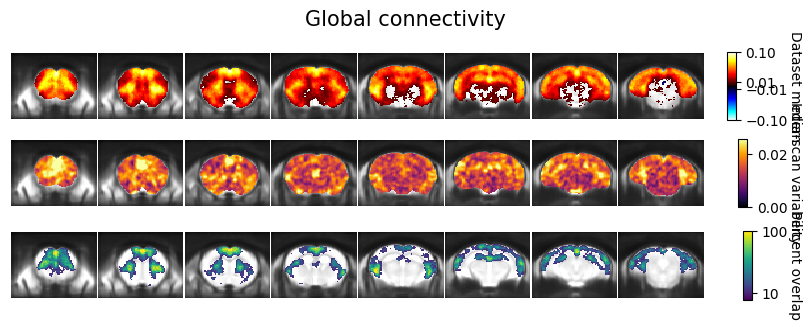

In [18]:
'''
Generate group-level statistical maps for global connectivity
'''
fig,axes = group_stats_QC_plot(
        GC_dict, 
        brain_mask_file, 
        template_file,
        slice_selection, 
        threshold=True, 
        vmax_FC=0.1, 
        include_stat=['avg', 'sd', 'overlap'],
        qc_data_dict={},
        )
fig.suptitle('Global connectivity', fontsize=15)
fig_path = f'figures_QC/{rabies_out_name}/{CR_name}/GC_group_stats_{rabies_out_name}.png'
fig.savefig(fig_path, bbox='tight')


In [19]:
'''
Generate RABIES-like dataset QC scatter plots for each selected ICA component
'''

FC_amp_list = [np.sqrt(GC_dict[img_id] ** 2).sum() for img_id in data_obj.img_id_list]
dice_list = qc_utils.get_dice_list(GC_dict, avg_type='median', top_percent=10)

net_metric_dict = {'Network amplitude':np.array(FC_amp_list), 'Network specificity (Dice)':np.array(dice_list)}
fig = plot_QC_distributions(net_metric_dict,qc_metric_dict, x_bounds_dict=x_bounds_dict, y_bounds_dict=y_bounds_dict, QC_inclusion=None, scan_QC_thresholds={}, outlier_threshold=3.5, write_corr=True)

fig_path = f'figures_QC/{rabies_out_name}/{CR_name}/GC_scatter_{rabies_out_name}.png'
fig.savefig(fig_path, bbox='tight')
plt.close()


/tmp/ipykernel_30012/2275361143.py:12: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "bbox" which is no longer supported as of 3.3 and will become an error two minor releases later
  fig.savefig(fig_path, bbox='tight')


## Example for dual regression

For dual regression I am first loading a ICA decomposition (the one from RABIES), to then computed dual regression and plot QC for a selected set of 3 components.

Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Generating a figure with dimensions (9.82222318649292, 2.880000114440918), 3 rows and 1 columns.


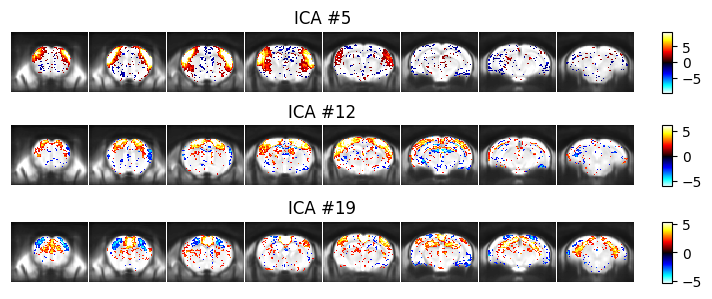

In [20]:
IC_file = '/home/vscode/.local/share/rabies/EPICOMMON/EPICOMMON_atlas/melodic_IC_resampled.nii.gz'
IC_idx = [5,12,19]
IC_name='EPICOMMON_ICs'


IC_arr = data_obj._load_img_to_masked_array(IC_file, data_type='continuous')
data_list = [IC_arr[i,:] for i in IC_idx]
if len(data_list)==1:
    data_list = data_list*2

plot_size_scale = 0.1
fig,ax_list,cbar_list = plotting.plot_many_brains(
        data_list,brain_mask_file,template_file,
        plot_size_scale=plot_size_scale,
        plane=plane, slice_selection=slice_selection, crop_edges=crop_edges, # slice selection
        cmap='cold_hot', vmax=None, vmin=None, plot_cbar=True, # cmap range
        percent_thresholding=True, top_percent=20)

i=0
for ax in ax_list:
    ax.set_title(f'ICA #{IC_idx[i]}', fontsize=12)
    i+=1

In [21]:
'''
Compute dual regression using the selected ICA components
'''
from rubella.basic_fc import compute_dual_regression
DR_dict = compute_dual_regression(timeseries_dict=data_obj.timeseries_dict, brain_mask=data_obj.brain_mask_file, img_id_list=data_obj.img_id_list, IC_maps=IC_arr, IC_idx=IC_idx)

In [22]:
'''
Generate group-level statistical maps for each selected ICA component
'''
num_ICs = len(IC_idx)
fig_set = {}
for i in range(num_ICs):
    FC_map_dict = {}
    for img_id in data_obj.img_id_list:
        FC_map_dict[img_id] = DR_dict[img_id]['DR_maps'][:,i]

    fig,axes = group_stats_QC_plot(FC_map_dict, brain_mask_file, template_file, slice_selection, threshold=True, include_stat=['avg', 'sd', 'overlap'], qc_data_dict={})
    fig.suptitle(f'DR ICA #{IC_idx[i]}', fontsize=15)
    fig_set[i] = fig
    plt.close(fig)

# Save all figures into one PDF
pdf_path = f"figures_QC/{rabies_out_name}/{CR_name}/DR_group_stats_{IC_name}_{rabies_out_name}.pdf"
with PdfPages(pdf_path) as pdf:
    for i in range(num_ICs):
        fig = fig_set[i]
        pdf.savefig(fig)


Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]
Plotting along slices: [31, 29, 27, 24, 22, 19, 17, 15]


In [23]:
'''
Generate RABIES-like dataset QC scatter plots for each selected ICA component
'''

num_ICs = len(IC_idx)
fig_set = {}
for i in range(num_ICs):
    FC_map_dict = {}
    for img_id in data_obj.img_id_list:
        FC_map_dict[img_id] = DR_dict[img_id]['DR_maps'][:,i]

    dice_list = qc_utils.get_dice_list(FC_map_dict, avg_FC=None, avg_type='median', top_percent=10)
    FC_amp_list = [np.sqrt(FC_map_dict[img_id] ** 2).sum() for img_id in FC_map_dict]
    net_metric_dict = {'Network amplitude':np.array(FC_amp_list), 'Network specificity (Dice)':np.array(dice_list)}

    fig = plot_QC_distributions(net_metric_dict,qc_metric_dict, x_bounds_dict=x_bounds_dict, y_bounds_dict=y_bounds_dict, QC_inclusion=None, scan_QC_thresholds={}, outlier_threshold=3.5, write_corr=True)
    fig.suptitle(f'ICA #{IC_idx[i]}', fontsize=30)
    fig_set[i] = fig
    plt.close(fig)

# Save all figures into one PDF
pdf_path = f"figures_QC/{rabies_out_name}/{CR_name}/DR_scatter_{IC_name}_{rabies_out_name}.pdf"
with PdfPages(pdf_path) as pdf:
    for i in range(num_ICs):
        fig = fig_set[i]
        pdf.savefig(fig)
